In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Scikit-Learn:", LinearRegression.__module__.split('.')[0])

Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Scikit-Learn: sklearn


In [3]:
df = pd.read_csv('data/train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#  Titanic Survival Prediction

## Objective
Build a Machine Learning model to predict whether a Titanic passenger survived.

## Problem Type
Binary Classification — predict `Survived` (0 = No, 1 = Yes).

## Dataset
Kaggle — Titanic: Machine Learning from Disaster

## 1. Exploratory Data Analysis (EDA)

In this section, we examine the dataset's structure, data types, missing values, and statistical properties before preprocessing.

In [30]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(891, 13)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
 12  FamilySize   891 non-null    int64  
dtypes: float64(2), int64(6), str(5)
memory usage: 90.6 KB
None
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin       

In [31]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [32]:
pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
)

Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


In [33]:
pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
)

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


In [34]:
df.groupby("Survived")["Age"].median()

Survived
0    28.0
1    28.0
Name: Age, dtype: float64

### 1.2 Age Distribution Analysis


In [35]:
df.groupby("Survived")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,424.0,30.626179,14.172110,1.00,21.0,28.0,39.0,74.0
1,290.0,28.343690,14.950952,0.42,19.0,28.0,36.0,80.0


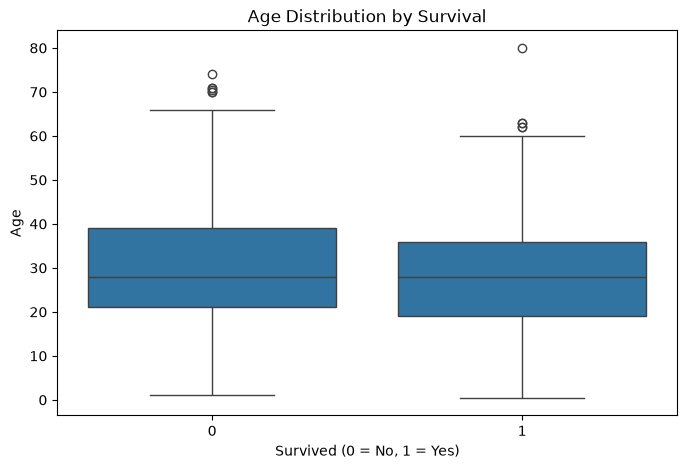

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Age"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

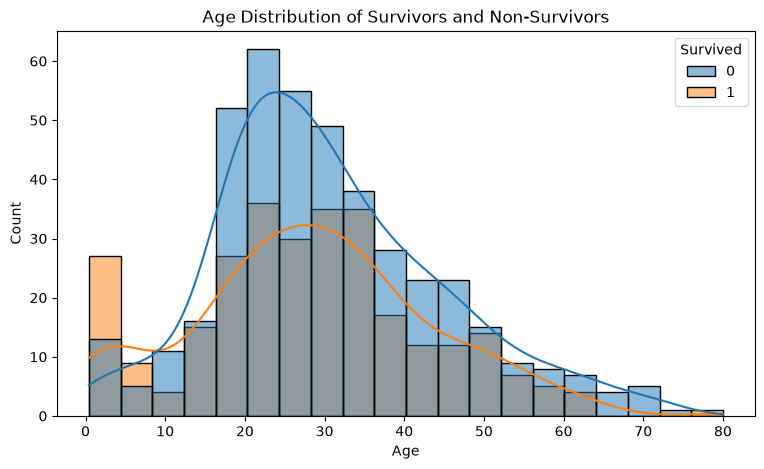

In [37]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Survivors and Non-Survivors")
plt.show()

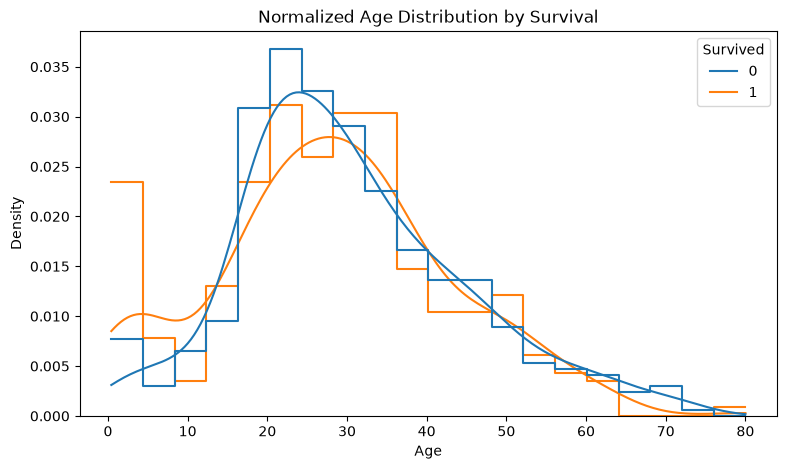

In [38]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    kde=True
)

plt.title("Normalized Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Density")

plt.show()

### Age Analysis - Observations

- Both survival groups have the same median age (28).
- Their age distributions overlap considerably.
- Younger passengers, particularly infants, show interesting survival patterns.
- Age may provide useful predictive information despite the overlapping distributions.

Decision: Retain Age for further investigation and model training.

### visualizing sex and pclass

In [39]:
sex_survival = df.groupby("Sex")["Survived"].mean() * 100

sex_survival

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

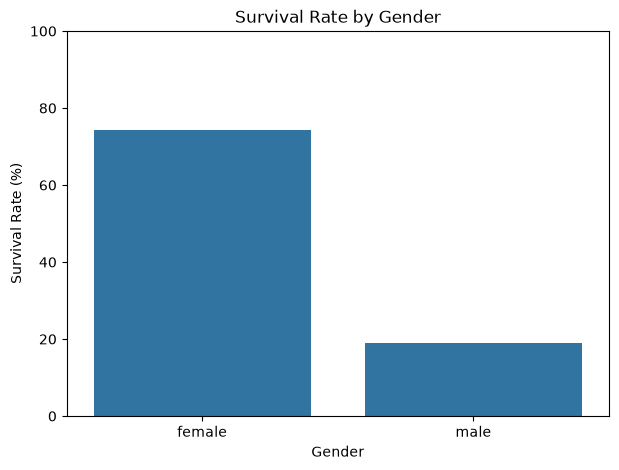

In [40]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=sex_survival.index,
    y=sex_survival.values
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

In [41]:
pclass_survival = df.groupby("Pclass")["Survived"].mean() * 100
pclass_survival

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

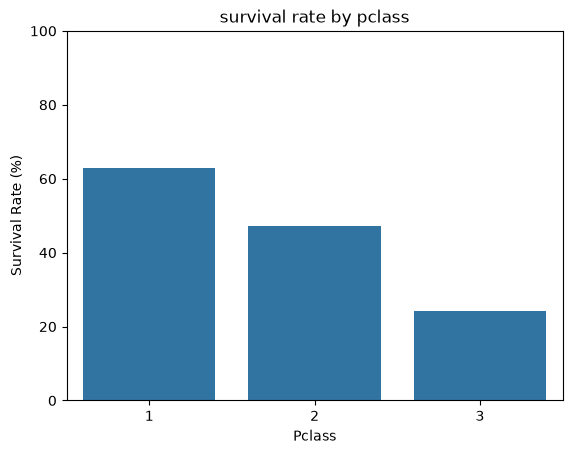

In [42]:
plt.Figure(figsize=(7,5))

sns.barplot(
    x=pclass_survival.index.astype(str),
    y=pclass_survival.values
)

plt.title("survival rate by pclass")
plt.xlabel("Pclass")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()

### Results: Survival by Sex and Passenger Class

#### 1. Survival by Gender

- Female passengers had a survival rate of approximately 74.20%.
- Male passengers had a survival rate of approximately 18.89%.
- A significantly higher proportion of female passengers survived.

**Observation:** Gender appears to be a strong feature associated with passenger survival.

#### 2. Survival by Passenger Class

- First-class passengers had the highest survival rate (62.96%).
- Second-class passengers had a survival rate of 47.28%.
- Third-class passengers had the lowest survival rate (24.24%).

**Observation:** Passenger class appears to be an important feature associated with survival.

#### Overall Conclusion

Both gender and passenger class show substantial differences in survival rates. Therefore, we will retain both features for model training and further investigation.

In [43]:
df["Embarked"].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [44]:
df.groupby("Embarked")["Survived"].mean() * 100

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64

In [45]:
pd.crosstab(
    df["Embarked"],
    df["Pclass"],
       normalize="index"
)

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


In [46]:
port_class_survival = df.groupby(
    ["Embarked", "Pclass"]
)["Survived"].agg(["count", "mean"])

port_class_survival["survival_rate_%"] = (
    port_class_survival["mean"] * 100
)

port_class_survival.drop(columns="mean")

count  survival_rate_%
Embarked Pclass                        
C        1          85        69.411765
         2          17        52.941176
         3          66        37.878788
Q        1           2        50.000000
         2           3        66.666667
         3          72        37.500000
S        1         127        58.267717
         2         164        46.341463
         3         353        18.980170

### Embarked Analysis - Observations

- Cherbourg had the highest overall survival rate (55.36%).
- Southampton had the lowest overall survival rate (33.70%).
- Cherbourg had a higher proportion of first-class passengers.
- Survival differences were also observed within individual passenger classes.
- Some port-class combinations had very small sample sizes.

Observation: Embarked may contain additional predictive information
beyond passenger class.

Decision: Retain Embarked for further investigation and model training.

In [47]:
df[["SibSp", "Parch"]].describe()

,SibSp,Parch
count,891.000000,891.000000
mean,0.523008,0.381594
std,1.102743,0.806057
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,0.000000
max,8.000000,6.000000


In [48]:
df["SibSp"].value_counts().sort_index()

SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

In [49]:
df["Parch"].value_counts().sort_index()

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

In [50]:
print(df.groupby("SibSp")["Survived"].mean() * 100 )
df.groupby("Parch")["Survived"].mean() * 100

SibSp
0    34.539474
1    53.588517
2    46.428571
3    25.000000
4    16.666667
5     0.000000
8     0.000000
Name: Survived, dtype: float64


Parch
0    34.365782
1    55.084746
2    50.000000
3    60.000000
4     0.000000
5    20.000000
6     0.000000
Name: Survived, dtype: float64

In [51]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
#the +1 is to include the passenger themselves in the family size calculation

In [52]:
family_summary = df.groupby("FamilySize")["Survived"].agg(
    ["count", "mean"]
)

family_summary["survival_rate_%"] = (
    family_summary["mean"] * 100
)

family_summary.drop(columns="mean")

,count,survival_rate_%
FamilySize,,
1,537,30.353818
2,161,55.279503
3,102,57.843137
4,29,72.413793
5,15,20.000000
6,22,13.636364
7,12,33.333333
8,6,0.000000
11,7,0.000000


### Family Size Analysis

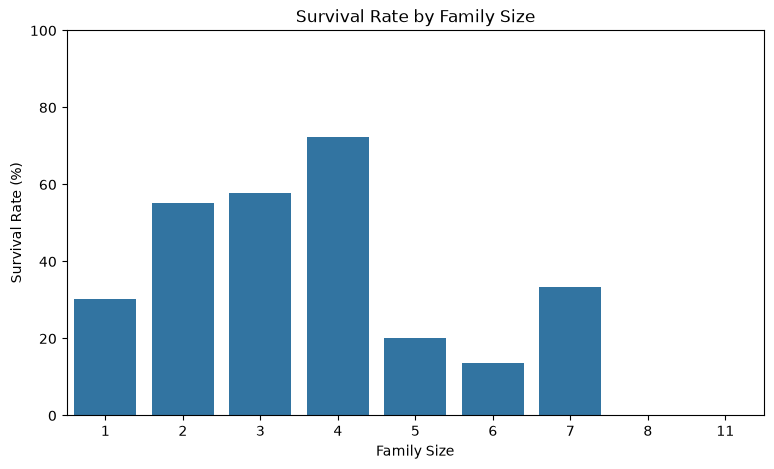

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=family_summary.index.astype(str),
    y=family_summary["survival_rate_%"],
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

### Family Size Analysis - Observations

- Passengers with a family size of 1 had a survival rate of 30.35%.
- Family sizes of 2–4 showed comparatively higher survival rates.
- Family size 4 had the highest observed survival rate (72.41%).
- Larger family groups generally showed lower survival rates.
- Some larger family groups had very small sample sizes, so their survival rates should be interpreted cautiously.

Observation: Family size may contain useful predictive information.

Decision: Retain FamilySize for further investigation and model training.

### Family Size - Feature Engineering Decision

- Created FamilySize by combining SibSp and Parch, including the passenger.
- FamilySize captures the total number of recorded family members aboard.
- SibSp and Parch will initially be excluded from model training to avoid redundant representations.

Decision: Use FamilySize as the initial family-related feature.

This decision will be evaluated during model comparison.